# Feature Selection & Transformation EDA

This notebook evaluates the engineered features to identify which features should be kept or dropped and determine suitable transformations for the selected features.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from src.storage.config import FEATURES_DB_DIR
from src.storage.data_io import load_data

# Load dataset
df = load_data(FEATURES_DB_DIR)

# Preview of Dataset

In [4]:
display(df.head(10))

,Customer_ID,Country,Date,Total_Invoice,Total_Quantity,Total_Amount,Unique_Products,Mean_Quantity,Max_Quantity,Min_Quantity,...,Customer_Span_Days,Days_Since_Last_Purchase,Unique_Purchase_Week_Days,Unique_Purchase_Dates,Mean_Days_Between_Purchases,Median_Days_Between_Purchases,Max_Days_Between_Purchases,Min_Days_Between_Purchases,Std_Days_Between_Purchases,Target
0,13085.0,UNITED KINGDOM,2009-12-01,6,728,2017.20,33,11.741935,48,2,...,59,224,3,3,11.600000,0.0,56.0,0.0,24.835459,0
1,13078.0,UNITED KINGDOM,2009-12-01,24,4072,11382.14,83,13.438944,160,2,...,276,7,6,23,11.608696,11.0,27.0,0.0,5.805476,1
2,15362.0,UNITED KINGDOM,2009-12-01,1,145,310.75,23,6.304348,12,1,...,0,283,1,1,NaN,NaN,NaN,NaN,NaN,1
3,18102.0,UNITED KINGDOM,2009-12-01,78,107180,269041.67,268,189.029982,816,2,...,273,10,6,36,3.272727,0.0,23.0,0.0,5.352413,1
4,12682.0,FRANCE,2009-12-01,16,3708,7596.18,154,10.716763,48,2,...,282,1,5,16,18.200000,16.0,40.0,3.0,10.241373,1
5,18087.0,UNITED KINGDOM,2009-12-01,9,2714,7964.34,39,42.406250,192,6,...,244,39,4,7,30.250000,25.0,110.0,0.0,35.236953,1
6,13635.0,UNITED KINGDOM,2009-12-01,2,477,797.15,38,11.925000,48,2,...,14,269,1,2,14.000000,14.0,14.0,14.0,NaN,1
7,14110.0,UNITED KINGDOM,2009-12-01,19,2725,6153.63,122,12.330317,48,2,...,269,14,5,18,14.555556,12.0,44.0,0.0,10.777003,1
8,17519.0,UNITED KINGDOM,2009-12-01,8,1722,2621.31,83,16.557692,96,1,...,219,64,5,8,31.000000,27.0,52.0,15.0,15.132746,1
9,13758.0,UNITED KINGDOM,2009-12-01,4,1847,3579.33,102,14.776000,96,1,...,148,134,3,4,49.333333,43.0,91.0,14.0,38.888730,1


# Dataset Basic Information

**Shape of dataframe:** 3,355 rows × 41 columns

**Missing values:** 8,385

**Duplicate rows:** 0

In [3]:
print("Shape of dataframe: ", df.shape)
print("Number of Missing Values: ", df.isnull().sum().sum())
print("Duplicate Values: ", df.duplicated().sum())
print("\nColumn Names: ", df.columns)
print(f"\nData types:\n{df.dtypes}")

Shape of dataframe:  (3355, 41)
Number of Missing Values:  8385
Duplicate Values:  0

Column Names:  Index(['Customer_ID', 'Country', 'Date', 'Total_Invoice', 'Total_Quantity',
       'Total_Amount', 'Unique_Products', 'Mean_Quantity', 'Max_Quantity',
       'Min_Quantity', 'Mean_Price', 'Median_Price', 'Std_Price',
       'Mean_Description_Length', 'Has_Multi_Description_Products',
       'Is_First_Purchase', 'Mean_Amount_Per_Product', 'Repeat_Product_Ratio',
       'Top_Product_Ratio', 'Mean_Products_Per_Invoice',
       'Mean_Unique_Products_Per_Invoice',
       'Median_Unique_Products_Per_Invoice', 'Mean_Quantity_Per_Invoice',
       'Mean_Amount_Per_Invoice', 'Median_Quantity_Per_Invoice',
       'Median_Amount_Per_Invoice', 'Max_Quantity_Per_Invoice',
       'Max_Amount_Per_Invoice', 'Std_Amount_Per_Invoice', 'Mode_Week_Day',
       'Mode_Hour', 'Customer_Span_Days', 'Days_Since_Last_Purchase',
       'Unique_Purchase_Week_Days', 'Unique_Purchase_Dates',
       'Mean_Days_Between

 # Customer_ID

**Decision: DROP JUST BEFORE MODELLING**

`Customer_ID` is an identifier rather than a predictive feature. It is retained during feature engineering to identify and group customers, but it should not be used as a model feature.

It will be excluded when creating the final **X (features)** and **y (target)** datasets.

In [37]:
# Basic Information
print(f"Customer ID data type: {df["Customer_ID"].dtypes}")
print(f"Number of missing values: {df['Customer_ID'].isnull().sum()}")
print(f"Number of unique values: {df['Customer_ID'].nunique()}")
print(f"Number of duplicate values: {df['Customer_ID'].duplicated().sum()}")

Customer ID data type: float64
Number of missing values: 0
Number of unique values: 3355
Number of duplicate values: 0


# Country

**Decision: KEEP**

`Country` is a categorical, nominal feature.

Due to the highly imbalanced distribution of countries and the small sample sizes of many categories, the feature will be grouped into four categories:

* `UNITED KINGDOM`
* `GERMANY`
* `FRANCE`
* `OTHERS`

The resulting categorical feature will be **One-Hot Encoded**.

In [2]:
# Basic Information
print(f"Data type: {df["Country"].dtypes}")
print(f"Number of unique countries: {df['Country'].nunique()}")
print(f"Number of missing values: {df['Country'].isnull().sum()}")
print(
    f"Avg country per Customer: {df.groupby('Customer_ID')['Country'].count().mean()}"
)

# Value Counts
print("-" * 15, " Value Counts ", "-" * 15)
print(df["Country"].value_counts())

# Relation between Country and Target
print("-" * 15, " Relation between Country and Target ", "-" * 15)
print(df.groupby("Country")["Target"].mean().sort_values(ascending=False))

# Country Group Analysis
print("-" * 15, " Country Group Analysis ", "-" * 15)
country_grouped = df["Country"].where(
    df["Country"].isin(["UNITED KINGDOM", "GERMANY", "FRANCE"]), "OTHERS"
)

print(df.groupby(country_grouped)["Target"].mean().sort_values(ascending=False))

Data type: str
Number of unique countries: 33
Number of missing values: 0
Avg country per Customer: 1.0
---------------  Value Counts  ---------------
Country
UNITED KINGDOM          3101
GERMANY                   59
FRANCE                    35
NETHERLANDS               18
SPAIN                     13
BELGIUM                   13
PORTUGAL                  11
SWEDEN                    11
SWITZERLAND               11
AUSTRIA                    9
DENMARK                    8
AUSTRALIA                  7
CHANNEL ISLANDS            7
CYPRUS                     7
ITALY                      7
FINLAND                    5
USA                        4
JAPAN                      4
EIRE                       3
GREECE                     3
UNITED ARAB EMIRATES       3
UNSPECIFIED                3
POLAND                     2
NORWAY                     2
MALTA                      1
RSA                        1
SINGAPORE                  1
BAHRAIN                    1
THAILAND                   1


# Date

**Decision: DROP**

`Date` should have been removed during feature engineering because it is not intended to be used directly as a model feature.

This was missed during feature engineering, so it will be removed at this stage.

# Total_Invoice

**Decision: TEST WITH AND WITHOUT UNIQUE_PURCHASE_DATES**

`Total_Invoice` represents the total number of invoices associated with each customer and is relevant to repeat-purchase behavior.

* **Correlation:** Pearson 0.229 and Spearman 0.374 on the original feature.
* **Distribution:** Highly right-skewed, with a skewness of 7.86.
* **Transformation:** Apply a `log1p` transformation. This reduces skewness to 1.36.
* **Correlation After `log1p`:** Pearson 0.361 and Spearman 0.374.
* **Reason for not keeping:** It has strong correlation with Unique_Purchase_Dates. Pearson 0.96 and Spearman 0.98.

Data type: int64
Number of missing values: 0
---------------  Statistics  ---------------
count    3355.000000
mean        3.669449
std         6.052652
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max       105.000000
Name: Total_Invoice, dtype: float64

Skewness: 7.8573183581164425
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        1.264814
std         0.631914
min         0.693147
25%         0.693147
50%         1.098612
75%         1.609438
max         4.663439
Name: Total_Invoice, dtype: float64

Skewness: 1.3568804108388581
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.2291493926575034
Pearson Correlation: 0.37422574200652226
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.3608397989166745
Pearson Correlation: 0.37422574200652226


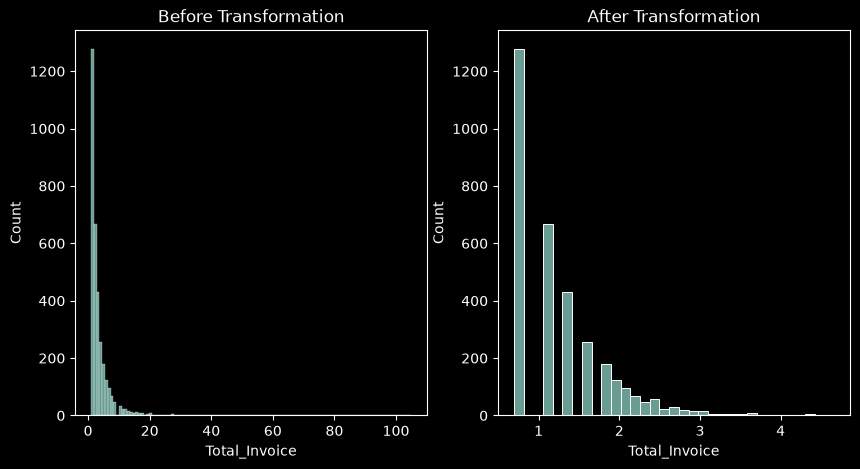

In [12]:
# Basic Information
print(f"Data type: {df["Total_Invoice"].dtypes}")
print(f"Number of missing values: {df["Total_Invoice"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Total_Invoice"].describe())
print(f"\nSkewness: {df['Total_Invoice'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Total_Invoice"]).describe())
print(f"\nSkewness: {np.log1p(df["Total_Invoice"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Total_Invoice"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Total_Invoice"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Total_Invoice"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Total_Invoice"]).corr(df["Target"], method="spearman")}"
)


# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Total_Invoice"], ax=axes[0])
sns.histplot(np.log1p(df["Total_Invoice"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Total_Quantity

**Decision: KEEP**

`Total_Quantity` represents the total quantity of products purchased by each customer and is relevant to repeat-purchase behavior.

* **Correlation:** Pearson 0.071 and Spearman 0.327 on the original feature.
* **Distribution:** Highly right-skewed, with a skewness of 22.57.
* **Transformation:** Apply a `log1p` transformation. This reduces skewness to 0.05.
* **Correlation After `log1p`:** Pearson 0.320 and Spearman 0.327.

Data type: int64
Number of missing values: 0
---------------  Statistics  ---------------
count      3355.000000
mean       1095.418480
std        6049.524738
min           1.000000
25%         131.000000
50%         328.000000
75%         835.000000
max      220596.000000
Name: Total_Quantity, dtype: float64

Skewness: 22.566279007848845
---------------  Statistics after using `log1p  ---------------
count    3355.000000
mean        5.810856
std         1.382117
min         0.693147
25%         4.882802
50%         5.796058
75%         6.728629
max        12.304093
Name: Total_Quantity, dtype: float64

Skewness: 0.05051053857256437
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.0709981309948264
Spearman Correlation: 0.3270331571106305
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.31979808845016655
Spearman Correlation: 0.3270331571106305


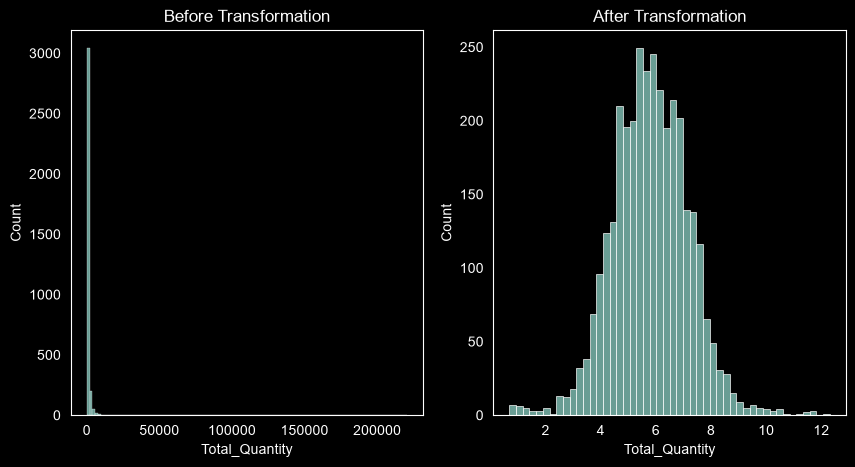

In [26]:
# Basic Information
print(f"Data type: {df["Total_Quantity"].dtypes}")
print(f"Number of missing values: {df["Total_Quantity"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Total_Quantity"].describe())
print(f"\nSkewness: {df['Total_Quantity'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Total_Quantity"]).describe())
print(f"\nSkewness: {np.log1p(df["Total_Quantity"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Total_Quantity"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Total_Quantity"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Total_Quantity"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Total_Quantity"]).corr(df["Target"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Total_Quantity"], ax=axes[0])
sns.histplot(np.log1p(df["Total_Quantity"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Total_Amount

**Decision: KEEP**

`Total_Amount` represents the total amount spent by each customer and is relevant to repeat-purchase behavior.

* **Correlation:** Pearson 0.109 and Spearman 0.356 on the original feature.
* **Distribution:** Highly right-skewed, with a skewness of 23.53.
* **Transformation:** Apply a `log1p` transformation. This reduces skewness to 0.25.
* **Correlation After `log1p`:** Pearson 0.345 and Spearman 0.356.

Data type: float64
Number of missing values: 0
---------------  Statistics  ---------------
count      3355.000000
mean       1657.118903
std        7247.163190
min           1.550000
25%         270.075000
50%         596.670000
75%        1407.530000
max      269041.670000
Name: Total_Amount, dtype: float64

Skewness: 23.525272316170724
---------------  Statistics after using `log1p  ---------------
count    3355.000000
mean        6.436330
std         1.249339
min         0.936093
25%         5.602395
50%         6.393039
75%         7.250302
max        12.502625
Name: Total_Amount, dtype: float64

Skewness: 0.24543968383178033
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.10879004861755665
Spearman Correlation: 0.3563724556702184
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.34472903010826905
Spearman Correlation: 0.3563724559533237


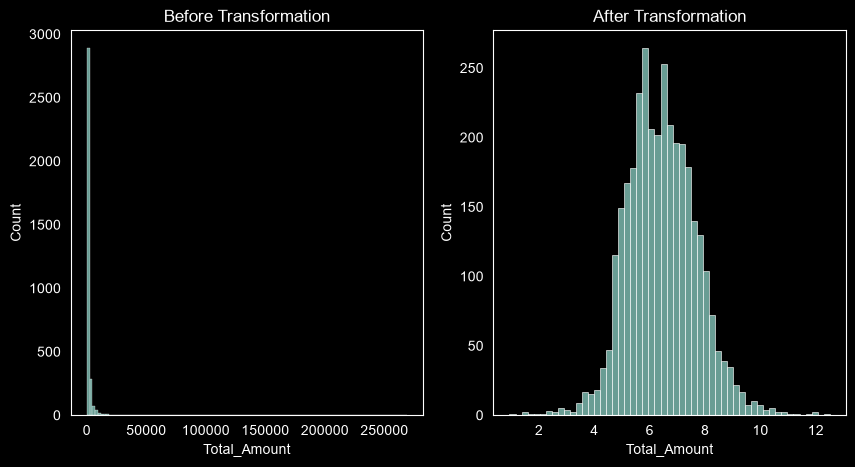

In [27]:
# Basic Information
print(f"Data type: {df["Total_Amount"].dtypes}")
print(f"Number of missing values: {df["Total_Amount"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Total_Amount"].describe())
print(f"\nSkewness: {df['Total_Amount'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Total_Amount"]).describe())
print(f"\nSkewness: {np.log1p(df["Total_Amount"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(f"Pearson Correlation: {df["Total_Amount"].corr(df["Target"], method="pearson")}")
print(
    f"Spearman Correlation: {df["Total_Amount"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Total_Amount"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Total_Amount"]).corr(df["Target"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Total_Amount"], ax=axes[0])
sns.histplot(np.log1p(df["Total_Amount"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Unique_Products

**Decision: KEEP**

`Unique_Products` represents the number of unique products purchased by each customer and is relevant to repeat-purchase behavior.

* **Correlation:** Pearson 0.247 and Spearman 0.329 on the original feature.
* **Distribution:** Right-skewed, with a skewness of 6.01.
* **Transformation:** Apply a `log1p` transformation. This reduces skewness to -0.27.
* **Correlation After `log1p`:** Pearson 0.317 and Spearman 0.329.

Data type: int64
Number of missing values: 0
---------------  Statistics  ---------------
count    3355.000000
mean       53.563636
std        71.940903
min         1.000000
25%        15.000000
50%        32.000000
75%        67.000000
max      1319.000000
Name: Unique_Products, dtype: float64

Skewness: 6.012133130519855
---------------  Statistics after using `log1p  ---------------
count    3355.000000
mean        3.450771
std         1.094003
min         0.693147
25%         2.772589
50%         3.496508
75%         4.219508
max         7.185387
Name: Unique_Products, dtype: float64

Skewness: -0.2684356125854966
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.24728749391254565
Spearman Correlation: 0.32894896332157175
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.31683067773968426
Spearman Correlation: 0.32894896332157175


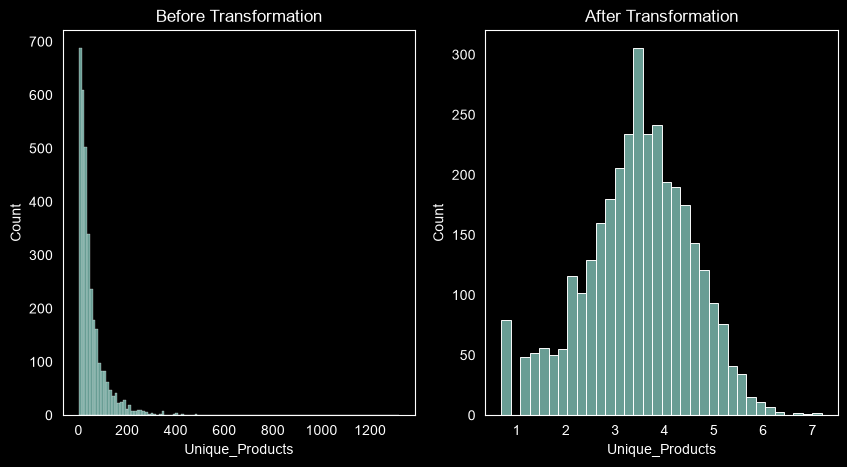

In [28]:
# Basic Information
print(f"Data type: {df["Unique_Products"].dtypes}")
print(f"Number of missing values: {df["Unique_Products"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Unique_Products"].describe())
print(f"\nSkewness: {df['Unique_Products'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Unique_Products"]).describe())
print(f"\nSkewness: {np.log1p(df["Unique_Products"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Unique_Products"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Unique_Products"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Unique_Products"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Unique_Products"]).corr(df["Target"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Unique_Products"], ax=axes[0])
sns.histplot(np.log1p(df["Unique_Products"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Mean_Quantity

**Decision: DROP**

`Mean_Quantity` represents the average quantity purchased per transaction by each customer.

* **Correlation:** Pearson -0.005 and Spearman 0.020 on the original feature.
* **Reason for dropping:** The feature shows almost no relationship with the target, and therefore does not provide meaningful evidence of repeat-purchase behavior.

In [30]:
# Basic Information
print(f"Data type: {df["Mean_Quantity"].dtypes}")
print(f"Number of missing values: {df["Mean_Quantity"].isnull().sum()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Quantity"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Mean_Quantity"].corr(df["Target"], method="spearman")}"
)

Data type: float64
Number of missing values: 0
---------------  Correlation  ---------------
Pearson Correlation: -0.00520280799627369
Spearman Correlation: 0.020417612749189358


# Max_Quantity

**Decision: DROP**

`Max_Quantity` represents the maximum quantity purchased in a single transaction by each customer.

* **Correlation:** Pearson 0.026 and Spearman 0.171 on the original feature.
* **Reason for dropping:** The feature has a weak relationship with the target and does not show a clear distribution pattern, even after transformation.

Data type: int64
Number of missing values: 0
---------------  Statistics  ---------------
count     3355.000000
mean        88.087034
std        443.172988
min          1.000000
25%         24.000000
50%         36.000000
75%         64.000000
max      19152.000000
Name: Max_Quantity, dtype: float64

Skewness: 29.994224560926526
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        3.676730
std         1.035200
min         0.693147
25%         3.218876
50%         3.610918
75%         4.174387
max         9.860215
Name: Max_Quantity, dtype: float64

Skewness: 0.6907507772890115
---------------  Correlation  ---------------
Pearson Correlation: 0.025511068744783767
Spearman Correlation: 0.17088237319071456
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.15984573893006396
Spearman Correlation: 0.17088237319071456


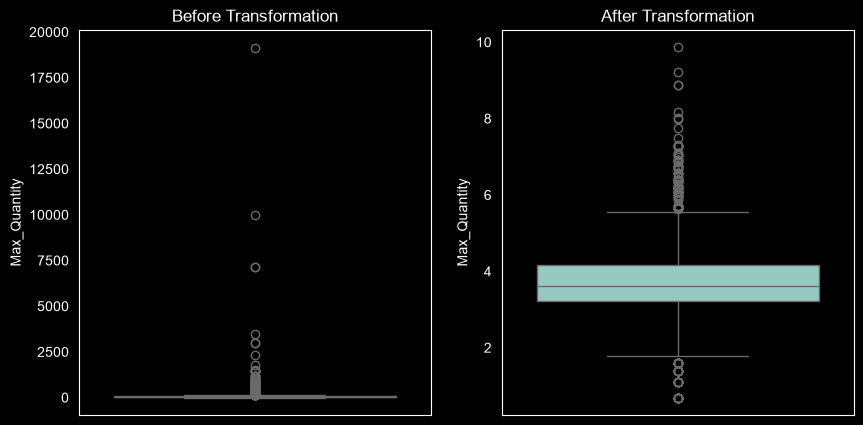

In [36]:
# Basic Information
print(f"Data type: {df["Max_Quantity"].dtypes}")
print(f"Number of missing values: {df["Max_Quantity"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Max_Quantity"].describe())
print(f"\nSkewness: {df['Max_Quantity'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Max_Quantity"]).describe())
print(f"\nSkewness: {np.log1p(df["Max_Quantity"]).skew()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Max_Quantity"].corr(df["Target"], method="pearson")}")
print(
    f"Spearman Correlation: {df["Max_Quantity"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Max_Quantity"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Max_Quantity"]).corr(df["Target"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.boxplot(df["Max_Quantity"], ax=axes[0])
sns.boxplot(np.log1p(df["Max_Quantity"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Min_Quantity

**Decision: DROP**

`Min_Quantity` represents the minimum quantity purchased in a single transaction by each customer.

* **Correlation:** Pearson -0.028 and Spearman -0.115 on the original feature.
* **Reason for dropping:** The feature shows a weak relationship with the target and does not provide meaningful evidence of repeat-purchase behavior.
* **Engineering:** Create a new feature `Range_Quantity`, because it has 0.203 Spearman Correlation which might be useful.

# Range_Quantity (Needs Engineering)

**Decision: TEST**

`Range_Quantity` represents the difference between maximum and minimum quantity purchased in a single transaction by each customer.

* **Correlation:** Pearson 0.203 and Spearman 0.03 on the original feature → positive relationship with the target.
* **Distribution:** Right-skewed, with a skewness of 31.5.
* **Transformation:** Apply a `log1p` transformation. This reduces skewness to -0.123.
* **Correlation After `log1p`:** Pearson 0.203 and Spearman 0.2 → stronger positive Pearson correlation.
* **Reason for decision:** It appears to be better than Min_Quantity and Max_Quantity and should be tested to see if it makes any change. It doesn't have a very strong relationship with target, and distribution is not so good. That's why it is not kept, but testing may make it kept.

Data type: int64
Number of missing values: 0
---------------  Correlation  ---------------
Pearson Correlation: -0.02820449301831718
Spearman Correlation: -0.11530648570634831
---------------  Correlation of range = max - min  ---------------
Pearson Correlation: 0.03004806461759196
Spearman Correlation: 0.2028298600556036
---------------  Statistics of range = max - min  ---------------
count     3355.000000
mean        80.367511
std        431.723411
min          0.000000
25%         19.000000
50%         31.000000
75%         59.000000
max      19146.000000
dtype: float64

Skewness: 31.497398465062457
---------------  Statistics of range = max - min after transformation  ---------------
count    3355.000000
mean        3.496865
std         1.199919
min         0.000000
25%         2.995732
50%         3.465736
75%         4.094345
max         9.859901
dtype: float64

Skewness: -0.12343973084522006
---------------  Correlation of range = max - min after transformation  --------------

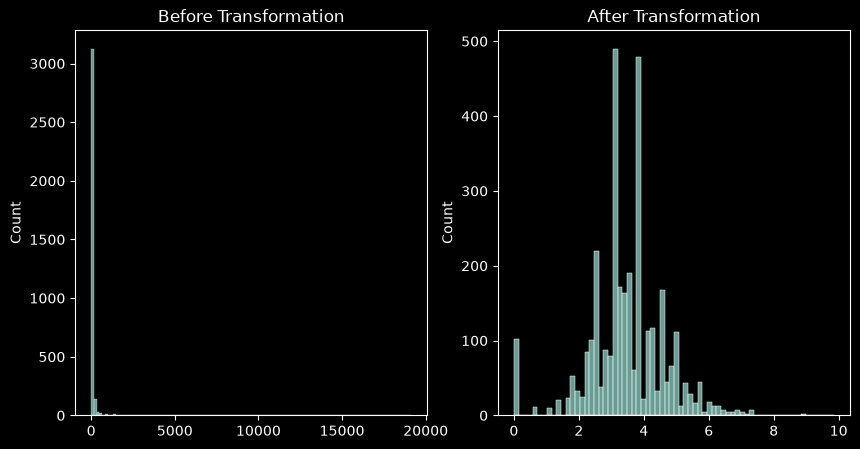

In [9]:
# Basic Information
print(f"Data type: {df["Min_Quantity"].dtypes}")
print(f"Number of missing values: {df["Min_Quantity"].isnull().sum()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Min_Quantity"].corr(df["Target"], method="pearson")}")
print(
    f"Spearman Correlation: {df["Min_Quantity"].corr(df["Target"], method="spearman")}"
)

# Correlation of range = max - min
print("-" * 15, " Correlation of range = max - min ", "-" * 15)
difference = df["Max_Quantity"] - df["Min_Quantity"]
print(f"Pearson Correlation: {difference.corr(df["Target"], method="pearson")}")
print(f"Spearman Correlation: {difference.corr(df["Target"], method="spearman")}")

# Statistics of range = max - min
print("-" * 15, " Statistics of range = max - min ", "-" * 15)
print(difference.describe())
print(f"\nSkewness: {difference.skew()}")

# Statistics of range = max - min after transformation
print("-" * 15, " Statistics of range = max - min after transformation ", "-" * 15)
print(np.log1p(difference).describe())
print(f"\nSkewness: {np.log1p(difference).skew()}")

# Correlation of range = max - min after transformation
print("-" * 15, " Correlation of range = max - min after transformation ", "-" * 15)
difference = df["Max_Quantity"] - df["Min_Quantity"]
print(
    f"Pearson Correlation: {np.log1p(difference).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(difference).corr(df["Target"], method="spearman")}"
)

# Visualization of range = max - min
print("-" * 15, " Visualization of range = max - min ", "-" * 15)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(difference, ax=axes[0])
sns.histplot(np.log1p(difference), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Mean_Price

**Decision: DROP**

`Mean_Price` represents the average price of products purchased by each customer.

* **Correlation:** Pearson -0.038 and Spearman -0.006 on the original feature.
* **Reason for dropping:** The feature shows almost no relationship with the target and therefore does not provide meaningful evidence of repeat-purchase behavior.

In [13]:
# Basic Information
print(f"Data type: {df["Mean_Price"].dtypes}")
print(f"Number of missing values: {df["Mean_Price"].isnull().sum()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Mean_Price"].corr(df["Target"], method="pearson")}")
print(f"Spearman Correlation: {df["Mean_Price"].corr(df["Target"], method="spearman")}")

Data type: float64
Number of missing values: 0
---------------  Correlation  ---------------
Pearson Correlation: -0.03821727808073741
Spearman Correlation: -0.006269040950811099


# Median_Price

**Decision: DROP**

`Median_Price` represents the median price of products purchased by each customer.

* **Correlation:** Pearson -0.051 and Spearman -0.045 on the original feature.
* **Reason for dropping:** The feature shows almost no relationship with the target and therefore does not provide meaningful evidence of repeat-purchase behavior.

In [15]:
# Basic Information
print(f"Data type: {df["Median_Price"].dtypes}")
print(f"Number of missing values: {df["Median_Price"].isnull().sum()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Median_Price"].corr(df["Target"], method="pearson")}")
print(
    f"Spearman Correlation: {df["Median_Price"].corr(df["Target"], method="spearman")}"
)

Data type: float64
Number of missing values: 0
---------------  Correlation  ---------------
Pearson Correlation: -0.05112569482215922
Spearman Correlation: -0.04507236630644491


# Std_Price

**Decision: DROP**

`Std_Price` represents the standard deviation of product prices purchased by each customer.

* **Missing values:** 68 (2.03%)
* **Correlation:** Pearson 0.018 and Spearman 0.054.
* **Reason for dropping:** The feature shows a very weak relationship with the target and requires additional missing-value handling, without providing meaningful evidence of repeat-purchase behavior.

In [17]:
# Basic Information
print(f"Data type: {df["Std_Price"].dtypes}")
print(f"Number of missing values: {df["Std_Price"].isnull().sum()}")
print(f"Percentage of missing values: {df["Std_Price"].isnull().mean() * 100}%")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Std_Price"].corr(df["Target"], method="pearson")}")
print(f"Spearman Correlation: {df["Std_Price"].corr(df["Target"], method="spearman")}")

Data type: float64
Number of missing values: 68
Percentage of missing values: 2.0268256333830106%
---------------  Correlation  ---------------
Pearson Correlation: 0.017742686146249007
Spearman Correlation: 0.05390041811115775


# Mean_Description_Length

**Decision: DROP**

`Mean_Description_Length` represents the average length of product descriptions purchased by each customer.

* **Correlation:** Pearson -0.039 and Spearman -0.043.
* **Reason for dropping:** The feature shows almost no relationship with the target and therefore does not provide meaningful evidence of repeat-purchase behavior.

In [18]:
# Basic Information
print(f"Data type: {df["Mean_Description_Length"].dtypes}")
print(f"Number of missing values: {df["Mean_Description_Length"].isnull().sum()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Description_Length"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Mean_Description_Length"].corr(df["Target"], method="spearman")}"
)

Data type: float64
Number of missing values: 0
---------------  Correlation  ---------------
Pearson Correlation: -0.03861915335604798
Spearman Correlation: -0.042529904088232845


# Has_Multi_Description_Products

**Decision: KEEP**

`Has_Multi_Description_Products` indicates whether a customer has purchased at least one product that appears with multiple descriptions. It is a binary feature.

* **Target rate:** 42.6% for customers with `0` and 62.4% for customers with `1`.
* **Reason for keeping:** The feature shows a noticeable difference in repeat-purchase rates between the two groups and may provide useful predictive information.

In [19]:
# Basic Information
print(f"Data type: {df["Has_Multi_Description_Products"].dtypes}")
print(
    f"Number of missing values: {df["Has_Multi_Description_Products"].isnull().sum()}"
)

# Value Counts
print("-" * 15, " Value Counts ", "-" * 15)
print(df["Has_Multi_Description_Products"].value_counts())

# Relationship between Has_Multi_Description_Products and Target
print(
    "-" * 15,
    " Relationship between Has_Multi_Description_Products and Target ",
    "-" * 15,
)
print(df.groupby("Has_Multi_Description_Products")["Target"].mean())

Data type: int64
Number of missing values: 0
---------------  Value Counts  ---------------
Has_Multi_Description_Products
1    2564
0     791
Name: count, dtype: int64
---------------  Relationship between Has_Multi_Description_Products and Target  ---------------
Has_Multi_Description_Products
0    0.426043
1    0.624025
Name: Target, dtype: float64


# Is_First_Purchase

**Decision: KEEP**

`Is_First_Purchase` indicates whether the customer's recorded purchase is their first purchase (has only one purchase so far). It is a binary feature.

* **Target rate:** 69.7% for customers with `0` and 38.3% for customers with `1`.
* **Reason for keeping:** The feature shows a clear difference in repeat-purchase rates between the two groups and may provide useful predictive information.

In [21]:
# Basic Information
print(f"Data type: {df["Is_First_Purchase"].dtypes}")
print(f"Number of missing values: {df["Is_First_Purchase"].isnull().sum()}")

# Value Counts
print("-" * 15, " Value Counts ", "-" * 15)
print(df["Is_First_Purchase"].value_counts())

# Relationship between Is_First_Purchase and Target
print("-" * 15, " Relationship between Is_First_Purchase and Target ", "-" * 15)
print(df.groupby("Is_First_Purchase")["Target"].mean())

Data type: int64
Number of missing values: 0
---------------  Value Counts  ---------------
Is_First_Purchase
0    2077
1    1278
Name: count, dtype: int64
---------------  Relationship between Is_First_Purchase and Target  ---------------
Is_First_Purchase
0    0.697159
1    0.382629
Name: Target, dtype: float64


# Mean_Amount_Per_Product

**Decision: DROP**

`Mean_Amount_Per_Product` represents the average amount spent per product by each customer.

* **Correlation:** Pearson 0.03 and Spearman 0.008 on the original feature.
* **Reason for dropping:** The feature shows a very weak relationship with the target, and therefore does not provide meaningful evidence of repeat-purchase behavior.

In [3]:
# Basic Information
print(f"Data type: {df["Mean_Amount_Per_Product"].dtypes}")
print(f"Number of missing values: {df["Mean_Amount_Per_Product"].isnull().sum()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Amount_Per_Product"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Mean_Amount_Per_Product"].corr(df["Target"], method="spearman")}"
)

Data type: float64
Number of missing values: 0
---------------  Correlation  ---------------
Pearson Correlation: 0.032793879985932674
Spearman Correlation: 0.0841390920143238


# Repeat_Product_Ratio

**Decision: KEEP**

`Repeat_Product_Ratio` represents the proportion of a customer's purchased products that were purchased repeatedly.

* **Correlation:** Pearson 0.263 and Spearman 0.346.
* **Distribution:** Moderately right-skewed, with a skewness of 2.00. The feature is bounded between 0 and 1 and has an acceptable distribution
* **Reason for keeping:** The feature shows a meaningful positive relationship with the target and may provide useful predictive information.

Data type: float64
Number of missing values: 0
---------------  Statistics  ---------------
count    3355.000000
mean        0.130536
std         0.183555
min         0.000000
25%         0.000000
50%         0.050000
75%         0.209934
max         1.000000
Name: Repeat_Product_Ratio, dtype: float64

Skewness: 1.999184659560682
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.2628775577570619
Spearman Correlation: 0.34563440945564455


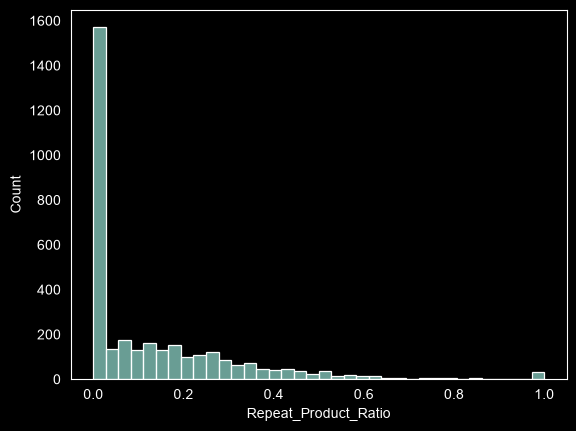

In [6]:
# Basic Information
print(f"Data type: {df["Repeat_Product_Ratio"].dtypes}")
print(f"Number of missing values: {df["Repeat_Product_Ratio"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Repeat_Product_Ratio"].describe())
print(f"\nSkewness: {df['Repeat_Product_Ratio'].skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Repeat_Product_Ratio"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Repeat_Product_Ratio"].corr(df["Target"], method="spearman")}"
)

# Visualization
sns.histplot(df["Repeat_Product_Ratio"])
plt.grid(False)
plt.show()

# Top_Product_Ratio

**Decision: TEST**

`Top_Product_Ratio` represents the proportion of a customer's purchases accounted for by their most frequently purchased product.

* **Correlation:** Pearson -0.146 and Spearman -0.212 → weak negative relationship with the target.
* **Distribution:** Highly right-skewed, with a skewness of 4.29.
* **Transformation:** Multiply the ratio by 100 to convert it to a percentage, then apply `log1p` to reduce the effect of the right skew.
* **Correlation After `log1p` transformation:** Pearson -0.157 and Spearman -0.212.
* **Reason for not keeping:** The feature shows a moderate negative relationship with the target, and the data is not properly distributed. Still it is not enough to drop the feature, so it would be tested during modeling.

Data type: float64
Number of missing values: 0
---------------  Statistics  ---------------
count    3355.000000
mean        0.095944
std         0.164234
min         0.004545
25%         0.028571
50%         0.047619
75%         0.083333
max         1.000000
Name: Top_Product_Ratio, dtype: float64

Skewness: 4.289089455906717
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        0.083447
std         0.118415
min         0.004535
25%         0.028171
50%         0.046520
75%         0.080043
max         0.693147
Name: Top_Product_Ratio, dtype: float64

Skewness: 3.7120267409273513
---------------  Correlation before transformation  ---------------
Pearson Correlation: -0.14641073831309168
Spearman Correlation: -0.21246861641509585
---------------  Correlation after transformation  ---------------
Pearson Correlation: -0.1573727896853985
Spearman Correlation: -0.21246861641509585


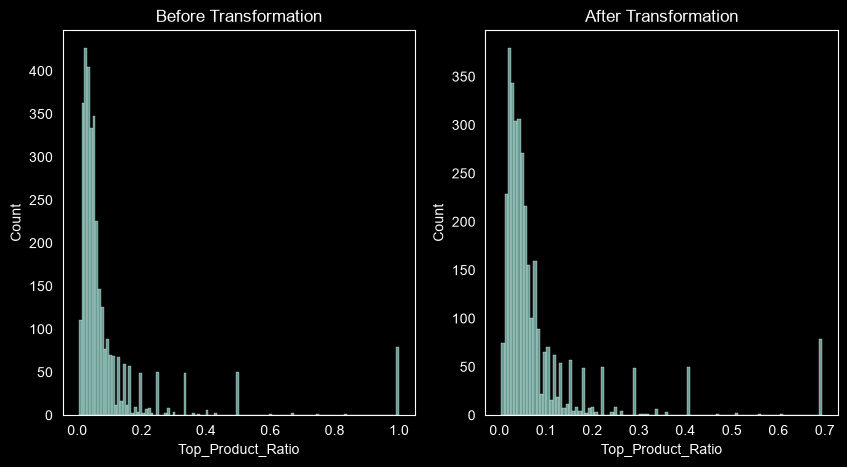

In [8]:
# Basic Information
print(f"Data type: {df["Top_Product_Ratio"].dtypes}")
print(f"Number of missing values: {df["Top_Product_Ratio"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Top_Product_Ratio"].describe())
print(f"\nSkewness: {df['Top_Product_Ratio'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Top_Product_Ratio"]).describe())
print(f"\nSkewness: {np.log1p(df["Top_Product_Ratio"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Top_Product_Ratio"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Top_Product_Ratio"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Top_Product_Ratio"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Top_Product_Ratio"]).corr(df["Target"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Top_Product_Ratio"], ax=axes[0])
sns.histplot(np.log1p(df["Top_Product_Ratio"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Mean_Products_Per_Invoice

**Decision: TEST**

`Mean_Products_Per_Invoice` represents the average number of products purchased per invoice by each customer.

* **Correlation:** Pearson 0.101 and Spearman 0.127.
* **Distribution:** Right-skewed, with a skewness of 2.70.
* **Transformation:** apply `log1p`. It decreases skewness to -0.44, substantially improving the distribution.
* **Correlation After `log1p`:** Pearson 0.134 and Spearman 0.127 → slightly stronger negative Pearson correlation.
* **Reason for not keeping:** The feature shows a weak negative relationship with the target, but there is a visible small relationship which might be helpful.

Data type: float64
Number of missing values: 0
---------------  Statistics  ---------------
count    3355.000000
mean       21.198662
std        18.113292
min         1.000000
25%         9.500000
50%        17.000000
75%        27.000000
max       240.000000
Name: Mean_Products_Per_Invoice, dtype: float64

Skewness: 2.7038271575133948
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        2.805735
std         0.808641
min         0.693147
25%         2.351375
50%         2.890372
75%         3.332205
max         5.484797
Name: Mean_Products_Per_Invoice, dtype: float64

Skewness: -0.4386606202130552
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.10053123665991562
Spearman Correlation: 0.1272672636672113
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.13415628603031507
Spearman Correlation: 0.1272672636672113


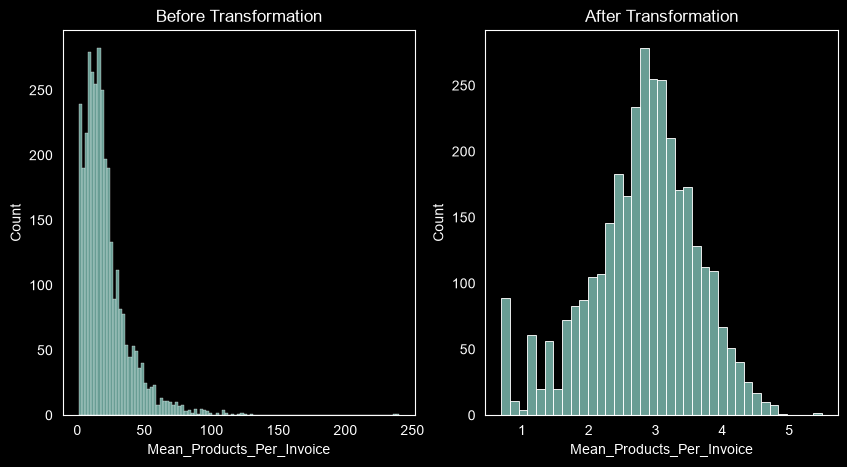

In [11]:
# Basic Information
print(f"Data type: {df["Mean_Products_Per_Invoice"].dtypes}")
print(f"Number of missing values: {df["Mean_Products_Per_Invoice"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Mean_Products_Per_Invoice"].describe())
print(f"\nSkewness: {df['Mean_Products_Per_Invoice'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Mean_Products_Per_Invoice"]).describe())
print(f"\nSkewness: {np.log1p(df["Mean_Products_Per_Invoice"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Products_Per_Invoice"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Mean_Products_Per_Invoice"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Mean_Products_Per_Invoice"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Mean_Products_Per_Invoice"]).corr(df["Target"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Mean_Products_Per_Invoice"], ax=axes[0])
sns.histplot(np.log1p(df["Mean_Products_Per_Invoice"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Mean_Unique_Products_Per_Invoice

**Decision: DROP**

`Mean_Unique_Products_Per_Invoice` represents the average number of unique products purchased per invoice by each customer.

* **Feature correlation:** Pearson 0.999 and Spearman 1.000 with `Mean_Products_Per_Invoice`.
* **Target correlation:** Pearson 0.100 and Spearman 0.128 → almost identical to `Mean_Products_Per_Invoice` (Pearson 0.101 and Spearman 0.127).
* **Reason for dropping:** The feature is highly redundant with `Mean_Products_Per_Invoice` and provides almost no additional information.

In [4]:
# Basic Information
print(f"Data type: {df["Mean_Unique_Products_Per_Invoice"].dtypes}")
print(
    f"Number of missing values: {df["Mean_Unique_Products_Per_Invoice"].isnull().sum()}"
)

# Correlation with Mean_Products_Per_Invoice
print("-" * 15, " Correlation with Mean_Products_Per_Invoice ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Unique_Products_Per_Invoice"].corr(df["Mean_Products_Per_Invoice"])}"
)
print(
    f"Spearman Correlation: {df["Mean_Unique_Products_Per_Invoice"].rank().corr(df["Mean_Products_Per_Invoice"].rank())}"
)

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Unique_Products_Per_Invoice"].corr(df["Target"])}"
)
print(
    f"Spearman Correlation: {df["Mean_Unique_Products_Per_Invoice"].rank().corr(df["Target"].rank())}"
)

Data type: float64
Number of missing values: 0
---------------  Correlation with Mean_Products_Per_Invoice  ---------------
Pearson Correlation: 0.9990614252425639
Spearman Correlation: 0.9995026114902399
---------------  Correlation  ---------------
Pearson Correlation: 0.10052455890994964
Spearman Correlation: 0.12774390804882763


# Median_Unique_Products_Per_Invoice

**Decision: DROP**

`Median_Unique_Products_Per_Invoice` represents the median number of unique products purchased per invoice by each customer.

* **Feature redundancy:** Pearson 0.984 and Spearman 0.978 with `Mean_Unique_Products_Per_Invoice`.
* **Target correlation:** Pearson 0.090 and Spearman 0.112.
* **Reason for dropping:** The feature is highly redundant with another feature and shows only a weak relationship with the target.

In [6]:
# Basic Information
print(f"Data type: {df["Median_Unique_Products_Per_Invoice"].dtypes}")
print(
    f"Number of missing values: {df["Median_Unique_Products_Per_Invoice"].isnull().sum()}"
)

# Correlation with Mean_Products_Per_Invoice
print("-" * 15, " Correlation with Mean_Products_Per_Invoice ", "-" * 15)
print(
    f"Pearson Correlation: {df["Median_Unique_Products_Per_Invoice"].corr(df["Mean_Products_Per_Invoice"])}"
)
print(
    f"Spearman Correlation: {df["Median_Unique_Products_Per_Invoice"].rank().corr(df["Mean_Products_Per_Invoice"].rank())}"
)

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Median_Unique_Products_Per_Invoice"].corr(df["Target"])}"
)
print(
    f"Spearman Correlation: {df["Median_Unique_Products_Per_Invoice"].rank().corr(df["Target"].rank())}"
)

Data type: float64
Number of missing values: 0
---------------  Correlation with Mean_Products_Per_Invoice  ---------------
Pearson Correlation: 0.9830313573870414
Spearman Correlation: 0.9769434334375658
---------------  Correlation  ---------------
Pearson Correlation: 0.08953593955410111
Spearman Correlation: 0.11246969274266146


# Mean_Quantity_Per_Invoice

**Decision: TEST**

`Mean_Quantity_Per_Invoice` represents the average quantity of products purchased per invoice by each customer.

* **Correlation:** Pearson 0.008 and Spearman 0.13 on the original feature → weak positive relationship with the target.
* **Distribution:** Highly right-skewed, with a skewness of 32.16.
* **Transformation:** Apply `log1p`. this decreases skewness to -0.33, substantially improving the distribution.
* **Correlation After `log1p`:** Pearson 0.137 and Spearman 0.130 → stronger positive Pearson correlation.
* **Reason for not keeping:** The feature's distribution improves substantially after transformation, and the transformed feature shows a positive relationship with the target. Still the correlation isn't strong enough to keep the feature without testing.

Data type: float64
Number of missing values: 0
---------------  Statistics  ---------------
count     3355.000000
mean       247.004586
std       1037.317683
min          1.000000
25%         84.000000
50%        148.666667
75%        259.253968
max      44119.200000
Name: Mean_Quantity_Per_Invoice, dtype: float64

Skewness: 32.162866739781656
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        4.975896
std         0.949920
min         0.693147
25%         4.442651
50%         5.008411
75%         5.561658
max        10.694673
Name: Mean_Quantity_Per_Invoice, dtype: float64

Skewness: -0.33385984828253507
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.007838774056539351
Spearman Correlation: 0.1299199339020956
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.1367764930535376
Spearman Correlation: 0.1299199339020956


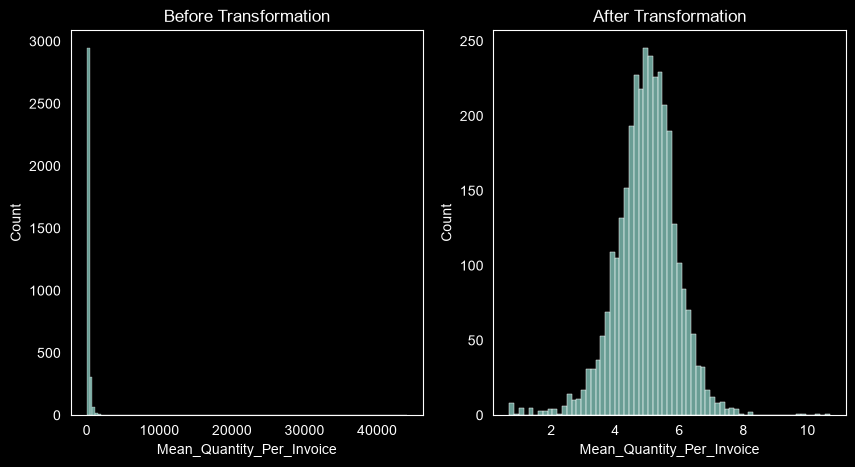

In [8]:
# Basic Information
print(f"Data type: {df["Mean_Quantity_Per_Invoice"].dtypes}")
print(f"Number of missing values: {df["Mean_Quantity_Per_Invoice"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Mean_Quantity_Per_Invoice"].describe())
print(f"\nSkewness: {df['Mean_Quantity_Per_Invoice'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Mean_Quantity_Per_Invoice"]).describe())
print(f"\nSkewness: {np.log1p(df["Mean_Quantity_Per_Invoice"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Quantity_Per_Invoice"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Mean_Quantity_Per_Invoice"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Mean_Quantity_Per_Invoice"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Mean_Quantity_Per_Invoice"]).corr(df["Target"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Mean_Quantity_Per_Invoice"], ax=axes[0])
sns.histplot(np.log1p(df["Mean_Quantity_Per_Invoice"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Mean_Amount_Per_Invoice

**Decision: TEST**

`Mean_Amount_Per_Invoice` represents the average amount spent per invoice by each customer.

* **Correlation:** Pearson 0.057 and Spearman 0.158 on the origina
* **Transformation:** Apply `log1p`. This decreases skewness to -0.33, substantially improving the distribution.
* **Correlation After `log1p`:** Pearson 0.155 and Spearman 0.158.
* **Reason for not keeping:** The feature's distribution improves substantially after transformation, and the transformed feature shows a positive relationship with the target. Still the correlation is not strong enough comparing with kept features to keep without testing.

Data type: float64
Number of missing values: 0
---------------  Statistics  ---------------
count     3355.000000
mean       363.267632
std        415.515337
min          1.550000
25%        171.210833
50%        284.425000
75%        414.793750
max      10877.180000
Name: Mean_Amount_Per_Invoice, dtype: float64

Skewness: 9.166749636175865
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        5.599294
std         0.764121
min         0.936093
25%         5.148719
50%         5.653979
75%         6.030189
max         9.294514
Name: Mean_Amount_Per_Invoice, dtype: float64

Skewness: -0.325589384238529
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.05688967450799606
Spearman Correlation: 0.15832777603299808
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.15479707311643182
Spearman Correlation: 0.15832746475426973


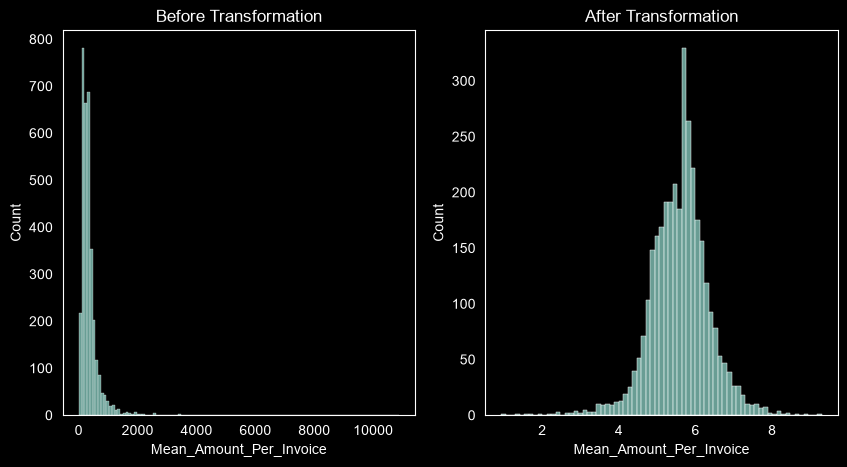

In [9]:
# Basic Information
print(f"Data type: {df["Mean_Amount_Per_Invoice"].dtypes}")
print(f"Number of missing values: {df["Mean_Amount_Per_Invoice"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Mean_Amount_Per_Invoice"].describe())
print(f"\nSkewness: {df['Mean_Amount_Per_Invoice'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Mean_Amount_Per_Invoice"]).describe())
print(f"\nSkewness: {np.log1p(df["Mean_Amount_Per_Invoice"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Amount_Per_Invoice"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Mean_Amount_Per_Invoice"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Mean_Amount_Per_Invoice"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Mean_Amount_Per_Invoice"]).corr(df["Target"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Mean_Amount_Per_Invoice"], ax=axes[0])
sns.histplot(np.log1p(df["Mean_Amount_Per_Invoice"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Median_Quantity_Per_Invoice

**Decision: DROP**

`Median_Quantity_Per_Invoice` represents the median quantity of products purchased per invoice by each customer.

* **Feature correlation:** Pearson 0.858 and Spearman 0.972 with `Mean_Quantity_Per_Invoice`.
* **Target correlation:** Pearson -0.011 and Spearman 0.11 → weak relationship with target.
* **Reason for dropping:** `Mean_Quantity_Per_Invoice` already captures similar information, so keeping both may add unnecessary redundancy. Additionally, it's relation with target is so weak.

Data type: float64
Number of missing values: 0
---------------  Statistics  ---------------
count     3355.000000
mean       231.804620
std       1181.630343
min          1.000000
25%         80.000000
50%        142.500000
75%        248.000000
max      63302.000000
Name: Median_Quantity_Per_Invoice, dtype: float64

Skewness: 46.95853468067016
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        4.921763
std         0.950395
min         0.693147
25%         4.394449
50%         4.966335
75%         5.517453
max        11.055688
Name: Median_Quantity_Per_Invoice, dtype: float64

Skewness: -0.3911160966541819
---------------  Correlation before transformation  ---------------
Pearson Correlation: -0.011089985643107009
Spearman Correlation: 0.11042680297359315
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.11576860309692148
Spearman Correlation: 0.11042680297359315
---------------  Correlation with Me

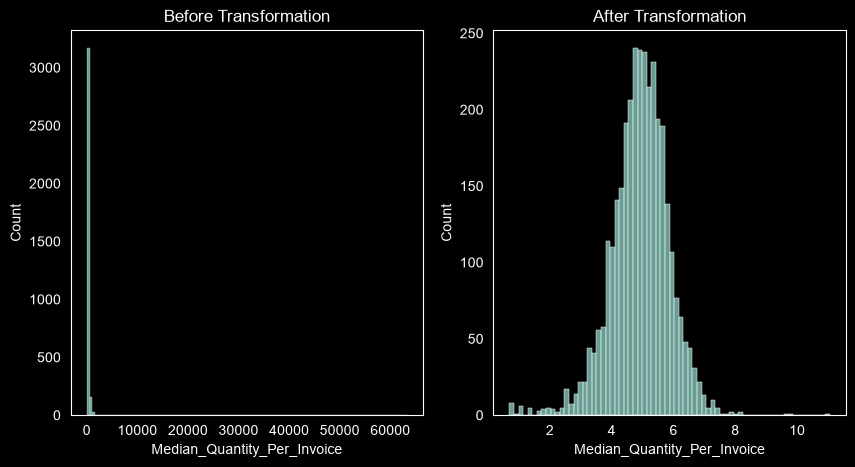

In [11]:
# Basic Information
print(f"Data type: {df["Median_Quantity_Per_Invoice"].dtypes}")
print(f"Number of missing values: {df["Median_Quantity_Per_Invoice"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Median_Quantity_Per_Invoice"].describe())
print(f"\nSkewness: {df['Median_Quantity_Per_Invoice'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Median_Quantity_Per_Invoice"]).describe())
print(f"\nSkewness: {np.log1p(df["Median_Quantity_Per_Invoice"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Median_Quantity_Per_Invoice"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Median_Quantity_Per_Invoice"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Median_Quantity_Per_Invoice"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Median_Quantity_Per_Invoice"]).corr(df["Target"], method="spearman")}"
)

# Correlation with Mean_Products_Per_Invoice
print("-" * 15, " Correlation with Mean_Products_Per_Invoice ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Quantity_Per_Invoice"].corr(df["Median_Quantity_Per_Invoice"])}"
)
print(
    f"Spearman Correlation: {df["Mean_Quantity_Per_Invoice"].rank().corr(df["Median_Quantity_Per_Invoice"].rank())}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Median_Quantity_Per_Invoice"], ax=axes[0])
sns.histplot(np.log1p(df["Median_Quantity_Per_Invoice"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

## Median_Quantity_Per_Invoice and Target

In [99]:
print(f"Pearson Correlation: {df["Median_Quantity_Per_Invoice"].corr(df["Target"])}")
print(
    f"Spearman Correlation: {df["Median_Quantity_Per_Invoice"].rank().corr(df["Target"].rank())}"
)

Pearson Correlation: -0.011089985643107009
Spearman Correlation: 0.11042680297359317


# Median_Amount_Per_Invoice

**Decision: DROP**

`Median_Amount_Per_Invoice` represents the median amount spent per invoice by each customer.

* **Feature correlation:** Pearson 0.960 and Spearman 0.973 with `Mean_Amount_Per_Invoice`.
* **Target correlation:** Pearson 0.037 and Spearman 0.138.
* **Reason for dropping:** `Mean_Amount_Per_Invoice` already captures very similar information, so keeping both would add unnecessary redundancy. Additionally, it's relation with target is not so strong.

In [13]:
# Basic Information
print(f"Data type: {df["Median_Amount_Per_Invoice"].dtypes}")
print(f"Number of missing values: {df["Median_Amount_Per_Invoice"].isnull().sum()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Median_Amount_Per_Invoice"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Median_Amount_Per_Invoice"].corr(df["Target"], method="spearman")}"
)

# Correlation with Mean_Amount_Per_Invoice
print("-" * 15, " Correlation with Mean_Amount_Per_Invoice ", "-" * 15)
print(
    f"Pearson Correlation: {df["Mean_Amount_Per_Invoice"].corr(df["Median_Amount_Per_Invoice"])}"
)
print(
    f"Spearman Correlation: {df["Mean_Amount_Per_Invoice"].rank().corr(df["Median_Amount_Per_Invoice"].rank())}"
)

Data type: float64
Number of missing values: 0
---------------  Correlation  ---------------
Pearson Correlation: 0.03726709994271415
Spearman Correlation: 0.13804380890826215
---------------  Correlation with Mean_Amount_Per_Invoice  ---------------
Pearson Correlation: 0.9597267703641275
Spearman Correlation: 0.9731264624280648


# Max_Quantity_Per_Invoice

**Decision: KEEP**

`Max_Quantity_Per_Invoice` represents the maximum quantity of products purchased in a single invoice by each customer.

* **Correlation:** Pearson 0.034 and Spearman 0.214 on the original feature.
* **Distribution:** Highly right-skewed, with a skewness of 30.64.
* **Transformation:** Apply `log1p`. It decreases skewness to -0.16, substantially improving the distribution.
* **Correlation After `log1p`:** Pearson 0.215 and Spearman 0.214.
* **Reason for keeping:** The transformed feature shows a positive relationship with the target, and its distribution improves substantially after transformation.

Data type: int64
Number of missing values: 0
---------------  Statistics  ---------------
count     3355.000000
mean       413.735022
std       2347.677528
min          1.000000
25%        103.000000
50%        203.000000
75%        377.000000
max      87167.000000
Name: Max_Quantity_Per_Invoice, dtype: float64

Skewness: 30.642218955207625
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        5.281299
std         1.067325
min         0.693147
25%         4.644391
50%         5.318120
75%         5.934894
max        11.375593
Name: Max_Quantity_Per_Invoice, dtype: float64

Skewness: -0.16418246004158185
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.03389744300353268
Spearman Correlation: 0.21353746225554562
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.2149273648337546
Spearman Correlation: 0.21353746225554562


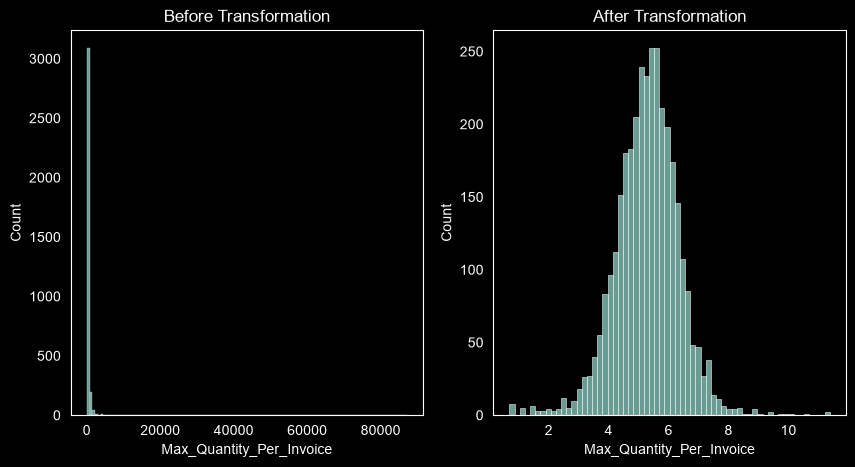

In [14]:
# Basic Information
print(f"Data type: {df["Max_Quantity_Per_Invoice"].dtypes}")
print(f"Number of missing values: {df["Max_Quantity_Per_Invoice"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Max_Quantity_Per_Invoice"].describe())
print(f"\nSkewness: {df['Max_Quantity_Per_Invoice'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Max_Quantity_Per_Invoice"]).describe())
print(f"\nSkewness: {np.log1p(df["Max_Quantity_Per_Invoice"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Max_Quantity_Per_Invoice"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Max_Quantity_Per_Invoice"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Max_Quantity_Per_Invoice"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Max_Quantity_Per_Invoice"]).corr(df["Target"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Max_Quantity_Per_Invoice"], ax=axes[0])
sns.histplot(np.log1p(df["Max_Quantity_Per_Invoice"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Max_Amount_Per_Invoice

**Decision: KEEP**

`Max_Amount_Per_Invoice` represents the maximum amount spent in a single invoice by each customer.

* **Correlation:** Pearson 0.093 and Spearman 0.243 on the original feature.
* **Distribution:** Highly right-skewed, with a skewness of 19.92.
* **Transformation:** Apply `log1p`. It  decreases skewness to -0.01, substantially improving the distribution.
* **Correlation After `log1p`:** Pearson 0.232 and Spearman 0.243.
* **Reason for keeping:** The transformed feature shows a positive relationship with the target, and its distribution improves substantially after transformation.

Data type: float64
Number of missing values: 0
---------------  Statistics  ---------------
count     3355.000000
mean       550.463094
std       1195.122918
min          1.550000
25%        204.500000
50%        346.900000
75%        587.695000
max      44051.600000
Name: Max_Amount_Per_Invoice, dtype: float64

Skewness: 19.915131307606295
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        5.860573
std         0.879130
min         0.936093
25%         5.325446
50%         5.851915
75%         6.377908
max        10.693140
Name: Max_Amount_Per_Invoice, dtype: float64

Skewness: -0.009835046370024057
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.09307865576751902
Spearman Correlation: 0.24314190061358984
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.23205499031220317
Spearman Correlation: 0.2431406551339086
---------------  Correlation with Max_Quantity

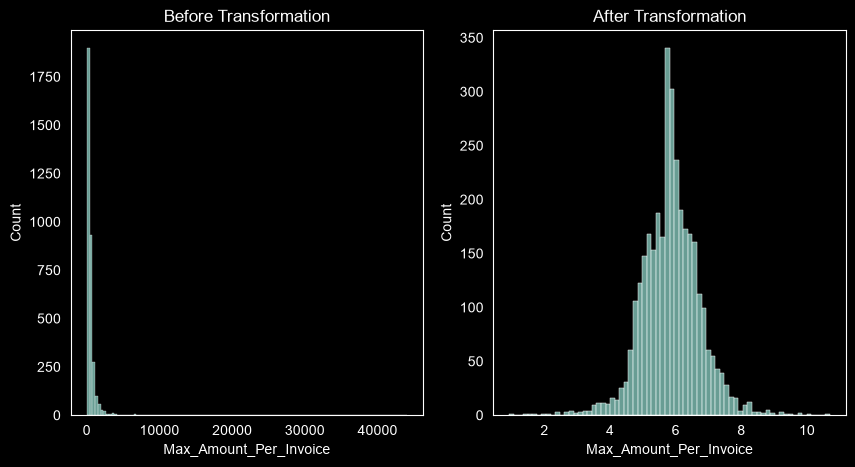

In [15]:
# Basic Information
print(f"Data type: {df["Max_Amount_Per_Invoice"].dtypes}")
print(f"Number of missing values: {df["Max_Amount_Per_Invoice"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Max_Amount_Per_Invoice"].describe())
print(f"\nSkewness: {df['Max_Amount_Per_Invoice'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Max_Amount_Per_Invoice"]).describe())
print(f"\nSkewness: {np.log1p(df["Max_Amount_Per_Invoice"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Max_Amount_Per_Invoice"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Max_Amount_Per_Invoice"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Max_Amount_Per_Invoice"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Max_Amount_Per_Invoice"]).corr(df["Target"], method="spearman")}"
)

# Correlation with Max_Quantity_Per_Invoice
print("-" * 15, " Correlation with Max_Quantity_Per_Invoice ", "-" * 15)
print(
    f"Pearson Correlation: {df["Max_Amount_Per_Invoice"].corr(df["Max_Quantity_Per_Invoice"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Max_Amount_Per_Invoice"].corr(df["Max_Quantity_Per_Invoice"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Max_Amount_Per_Invoice"], ax=axes[0])
sns.histplot(np.log1p(df["Max_Amount_Per_Invoice"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Std_Amount_Per_Invoice

**Decision: DROP**

`Std_Amount_Per_Invoice` represents the standard deviation of the amount spent across invoices by each customer.

* **Correlation:** Pearson 0.041 and Spearman 0.086.
* **Missing values:** 38.09%. Missing because customers with only one invoice cannot have a standard deviation across invoices.
* **Reason for dropping:** The feature has a very weak relationship with the target and a substantial amount of missing values due to customers having only one invoice.

In [16]:
# Basic Information
print(f"Data type: {df["Std_Amount_Per_Invoice"].dtypes}")
print(f"Number of missing values: {df["Std_Amount_Per_Invoice"].isnull().sum()}")
print(
    f"Percentage of missing values: {df["Std_Amount_Per_Invoice"].isnull().mean() * 100}"
)

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Std_Amount_Per_Invoice"].corr(df["Target"])}")
print(
    f"Spearman Correlation: {df["Std_Amount_Per_Invoice"].rank().corr(df["Target"].rank())}"
)

Data type: float64
Number of missing values: 1278
Percentage of missing values: 38.092399403874815
---------------  Correlation  ---------------
Pearson Correlation: 0.04067651857666085
Spearman Correlation: 0.08645253052240559


# Mode_Week_Day

**Decision: TEST**

**Type:** Nominal Categorical

`Mode_Week_Day` represents the most frequently occurring day of the week on which each customer made purchases.

* **Categories:** group the original 7 days into 3 categories:
  * `Mon_Tue_Wed`
  * `Thu_Fri`
  * `Sat_Sun`
* **Relation with Target:** Mean Target
  * `Mon_Tue_Wed`: 0.556
  * `Thu_Fri`: 0.592
  * `Sat_Sun`: 0.613
* **Reason for grouping:** Saturday has only 2 customers, making its target rate unreliable. Grouping days with similar target rates also reduces the number of categories.
* **Encoding:** One-hot encoding.
* **Reason for not keeping:** The difference in mean target of categories doesn't seem so helpful.

In [19]:
# Basic Information
print(f"Data type: {df["Mode_Week_Day"].dtypes}")
print(f"Number of missing values: {df["Mode_Week_Day"].isnull().sum()}")

# Value Counts
print("-" * 15, " Value Counts ", "-" * 15)
print(df["Mode_Week_Day"].value_counts())

# Mode_Week_Day and Target
print("-" * 15, " Mode_Week_Day and Target ", "-" * 15)
print(df.groupby("Mode_Week_Day")["Target"].mean().sort_values())

# Relation with Target after grouping
print("-" * 15, " Relation with Target after grouping ", "-" * 15)
mon_tue_wed = df[df["Mode_Week_Day"].isin(["Monday", "Tuesday", "Wednesday"])]
pre_weekend = df[df["Mode_Week_Day"].isin(["Thursday", "Friday"])]
weekend = df[df["Mode_Week_Day"].isin(["Saturday", "Sunday"])]
print(mon_tue_wed["Target"].mean())
print(pre_weekend["Target"].mean())
print(weekend["Target"].mean())

Data type: str
Number of missing values: 0
---------------  Value Counts  ---------------
Mode_Week_Day
Thursday     711
Wednesday    601
Tuesday      569
Sunday       520
Monday       512
Friday       440
Saturday       2
Name: count, dtype: int64
---------------  Mode_Week_Day and Target  ---------------
Mode_Week_Day
Saturday     0.000000
Monday       0.550781
Tuesday      0.558875
Wednesday    0.559068
Friday       0.584091
Thursday     0.596343
Sunday       0.615385
Name: Target, dtype: float64
---------------  Relation with Target after grouping  ---------------
0.5564803804994055
0.5916594265855778
0.6130268199233716


# Mode_Hour

**Decision: DROP**

`Mode_Hour` represents the most frequently occurring hour at which each customer made purchases.

* **Correlation:** Pearson -0.041 and Spearman -0.042.
* **Distribution:** Several categories have very few observations, such as hour 7 (6 customers), hour 18 (26), hour 19 (28), and hour 20 (7).
* **Target rates:** Target rates fluctuate across hours without a clear or consistent pattern.
* **Reason for dropping:** The feature has negligible correlation with the target, and the target rates for several low-frequency categories are unreliable. Target rates show no clear pattern.

Data type: int64
Number of missing values: 0
Number of unique values: 14
---------------  Correlation  ---------------
Pearson Correlation: -0.041102345813728326
Spearman Correlation: -0.04187864102879135
---------------  Value Counts  ---------------
Mode_Hour
7       6
8      75
9     235
10    360
11    438
12    578
13    529
14    419
15    359
16    196
17     99
18     26
19     28
20      7
Name: count, dtype: int64


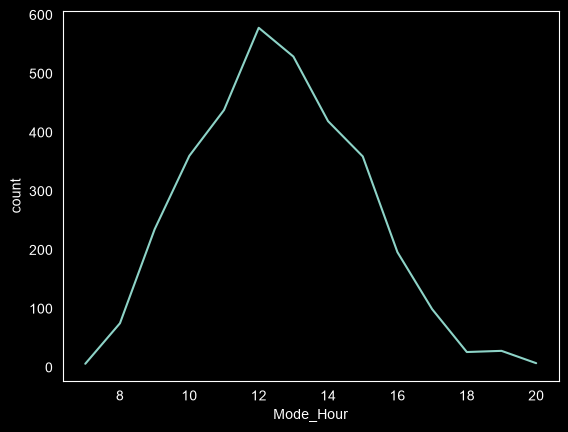

---------------  Mode_Hour and Target  ---------------
Mode_Hour
7     0.500000
8     0.626667
9     0.574468
10    0.591667
11    0.605023
12    0.586505
13    0.595463
14    0.594272
15    0.504178
16    0.545918
17    0.484848
18    0.461538
19    0.714286
20    0.428571
Name: Target, dtype: float64


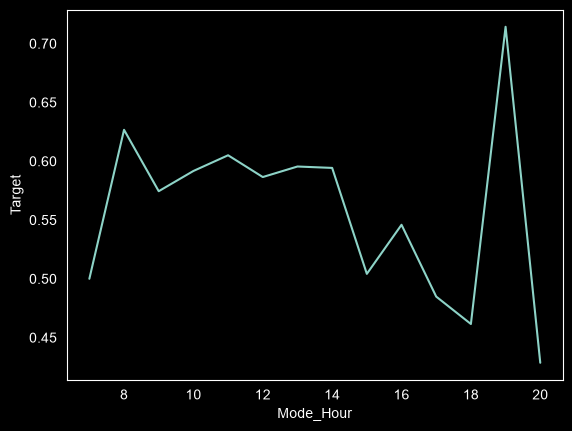

In [20]:
# Basic Information
print(f"Data type: {df["Mode_Hour"].dtypes}")
print(f"Number of missing values: {df["Mode_Hour"].isnull().sum()}")
print(f"Number of unique values: {df["Mode_Hour"].nunique()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Mode_Hour"].corr(df["Target"])}")
print(f"Spearman Correlation: {df["Mode_Hour"].rank().corr(df["Target"].rank())}")

# Value Counts
print("-" * 15, " Value Counts ", "-" * 15)
print(df["Mode_Hour"].value_counts().sort_index())
sns.lineplot(df["Mode_Hour"].value_counts())
plt.grid(False)
plt.show()

# Mode_Hour and Target
print("-" * 15, " Mode_Hour and Target ", "-" * 15)
print(df.groupby("Mode_Hour")["Target"].mean())
sns.lineplot(df.groupby("Mode_Hour")["Target"].mean())
plt.grid(False)
plt.show()

# Customer_Span_Days

**Decision: DROP**

`Customer_Span_Days` represents the number of days between a customer's first and last purchase.

* **Correlation:** Pearson -0.041 and Spearman -0.042.
* **Reason for dropping:** The feature shows almost no relationship with the target, providing little evidence of predictive value.

In [21]:
# Basic Information
print(f"Data type: {df["Customer_Span_Days"].dtypes}")
print(f"Number of missing values: {df["Customer_Span_Days"].isnull().sum()}")

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Mode_Hour"].corr(df["Target"])}")
print(f"Spearman Correlation: {df["Mode_Hour"].rank().corr(df["Target"].rank())}")

Data type: int64
Number of missing values: 0
---------------  Correlation  ---------------
Pearson Correlation: -0.041102345813728326
Spearman Correlation: -0.04187864102879135


# Days_Since_Last_Purchase

**Decision: KEEP**

`Days_Since_Last_Purchase` represents the number of days since each customer's most recent purchase relative to the reference date.

* **Correlation:** Pearson -0.261 and Spearman -0.261.
* **Distribution:** Moderately right-skewed, with a skewness of 0.80.
* **Transformation:** No transformation needed.
* **Reason for keeping:** The feature shows a meaningful negative relationship with the target, while its distribution is reasonably acceptable without transformation.

Data type: int64
Number of missing values: 0
---------------  Statistics  ---------------
count    3355.000000
mean       92.535917
std        77.355182
min         0.000000
25%        26.000000
50%        73.000000
75%       141.000000
max       283.000000
Name: Days_Since_Last_Purchase, dtype: float64

Skewness: 0.7951243195922124


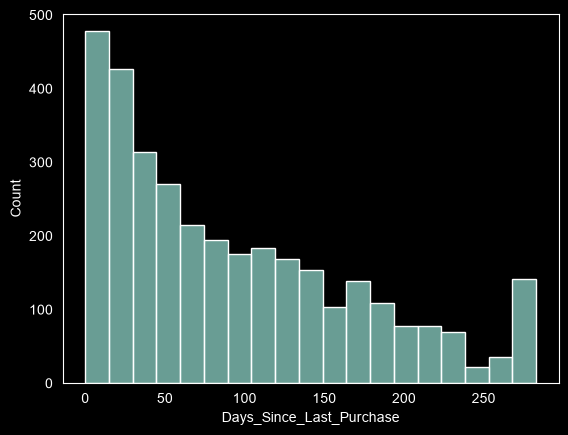

---------------  Correlation  ---------------
Pearson Correlation: -0.26072324542510056
Spearman Correlation: -0.2609671788626596


In [22]:
# Basic Information
print(f"Data type: {df["Days_Since_Last_Purchase"].dtypes}")
print(f"Number of missing values: {df["Days_Since_Last_Purchase"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Days_Since_Last_Purchase"].describe())
print(f"\nSkewness: {df["Days_Since_Last_Purchase"].skew()}")

# Visualization
sns.histplot(df["Days_Since_Last_Purchase"])
plt.grid(False)
plt.show()

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Days_Since_Last_Purchase"].corr(df["Target"])}")
print(
    f"Spearman Correlation: {df["Days_Since_Last_Purchase"].rank().corr(df["Target"].rank())}"
)

# Unique_Purchase_Week_Days

**Decision: KEEP**

`Unique_Purchase_Week_Days` represents the number of different days of the week on which each customer made purchases.

* **Type:** Ordinal numerical → values have a meaningful order from 1 to 7.
* **Distribution:** Most customers purchased on 1–3 unique days, while 7 days has only 4 customers.
* **Target rates:** Increase substantially as the number of unique purchase days increases, from 0.411 for 1 day to 1.000 for 7 days.
* **Correlation:** Pearson 0.337 and Spearman 0.347.
* **Encoding:** Keep as a numerical feature; no one-hot encoding is required.
* **Reason for keeping:** The feature shows a clear positive relationship with the target, and its ordinal nature is preserved by keeping it as a numeric feature.

## Basic Information

In [46]:
print(f"Data type: {df["Unique_Purchase_Week_Days"].dtypes}")
print(f"Number of missing values: {df["Unique_Purchase_Week_Days"].isnull().sum()}")

Data type: int64
Number of missing values: 0


## Value Counts

In [47]:
print(df["Unique_Purchase_Week_Days"].value_counts())

Unique_Purchase_Week_Days
1    1522
2     868
3     469
4     258
5     146
6      88
7       4
Name: count, dtype: int64


## Unique_Purchase_Week_Days and Target

In [50]:
print(df.groupby("Unique_Purchase_Week_Days")["Target"].mean())

Unique_Purchase_Week_Days
1    0.411301
2    0.614055
3    0.729211
4    0.844961
5    0.924658
6    0.897727
7    1.000000
Name: Target, dtype: float64


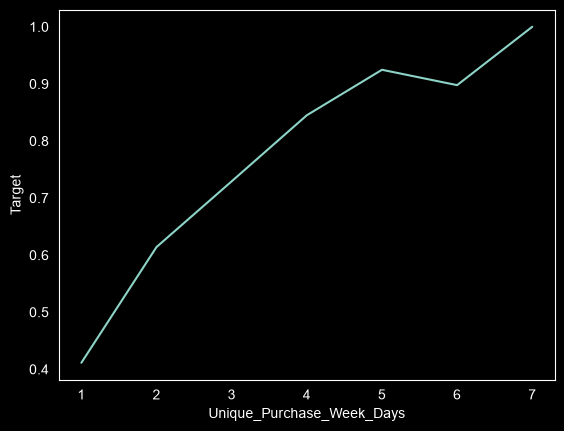

In [49]:
sns.lineplot(df.groupby("Unique_Purchase_Week_Days")["Target"].mean())
plt.grid(False)
plt.show()

## Correlation

In [51]:
print(f"Pearson Correlation: {df["Unique_Purchase_Week_Days"].corr(df["Target"])}")
print(
    f"Spearman Correlation: {df["Unique_Purchase_Week_Days"].rank().corr(df["Target"].rank())}"
)

Pearson Correlation: 0.33681562439135604
Spearman Correlation: 0.34674778788454397


# Unique_Purchase_Dates

**Decision: TEST WITH AND WITHOUT TOTAL_INVOICE**

`Unique_Purchase_Dates` represents the number of different calendar dates on which each customer made purchases.

* **Correlation:** Pearson 0.256 and Spearman 0.383 on the original feature.
* **Distribution:** Highly right-skewed, with skewness 7.06.
* **Transformation:** Apply `log1p`. Skewness decreased to 1.31, substantially improving the distribution.
* **Correlation After `log1p`:** Pearson 0.371 and Spearman 0.383.
* **Reason for not keeping:** Meaningful positive relationship with target, stronger Pearson correlation after transformation, and substantially reduced skewness. The reason for not keeping is its correlation with Total_Invoice (Pearson 0.96, Spearman 0.98).

Data type: int64
Number of missing values: 0
---------------  Statistics  ---------------
count    3355.000000
mean        3.290909
std         4.704952
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max        81.000000
Name: Unique_Purchase_Dates, dtype: float64

Skewness: 7.05766840849758
---------------  Statistics after using `log1p`  ---------------
count    3355.000000
mean        1.222107
std         0.594170
min         0.693147
25%         0.693147
50%         1.098612
75%         1.609438
max         4.406719
Name: Unique_Purchase_Dates, dtype: float64

Skewness: 1.3058827958218544
---------------  Correlation before transformation  ---------------
Pearson Correlation: 0.25595304693988236
Spearman Correlation: 0.3831912694897591
---------------  Correlation after transformation  ---------------
Pearson Correlation: 0.37136629582046393
Spearman Correlation: 0.3831912694897591
---------------  Correlation  with Total_Invoice  --------------

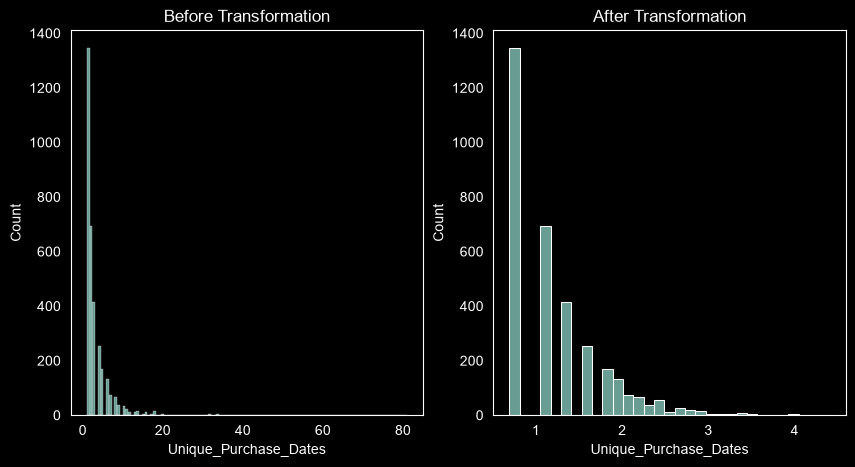

In [24]:
# Basic Information
print(f"Data type: {df["Unique_Purchase_Dates"].dtypes}")
print(f"Number of missing values: {df["Unique_Purchase_Dates"].isnull().sum()}")

# Statistics
print("-" * 15, " Statistics ", "-" * 15)
print(df["Unique_Purchase_Dates"].describe())
print(f"\nSkewness: {df['Unique_Purchase_Dates'].skew()}")

# Statistics after using `log1p`
print("-" * 15, " Statistics after using `log1p` ", "-" * 15)
print(np.log1p(df["Unique_Purchase_Dates"]).describe())
print(f"\nSkewness: {np.log1p(df["Unique_Purchase_Dates"]).skew()}")

# Correlation
print("-" * 15, " Correlation before transformation ", "-" * 15)
print(
    f"Pearson Correlation: {df["Unique_Purchase_Dates"].corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Unique_Purchase_Dates"].corr(df["Target"], method="spearman")}"
)
print("-" * 15, " Correlation after transformation ", "-" * 15)
print(
    f"Pearson Correlation: {np.log1p(df["Unique_Purchase_Dates"]).corr(df["Target"], method="pearson")}"
)
print(
    f"Spearman Correlation: {np.log1p(df["Unique_Purchase_Dates"]).corr(df["Target"], method="spearman")}"
)

# Correlation with Total_Invoice
print("-" * 15, " Correlation  with Total_Invoice ", "-" * 15)
print(
    f"Pearson Correlation: {df["Unique_Purchase_Dates"].corr(df["Total_Invoice"], method="pearson")}"
)
print(
    f"Spearman Correlation: {df["Unique_Purchase_Dates"].corr(df["Total_Invoice"], method="spearman")}"
)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df["Unique_Purchase_Dates"], ax=axes[0])
sns.histplot(np.log1p(df["Unique_Purchase_Dates"]), ax=axes[1])
axes[0].set_title("Before Transformation")
axes[1].set_title("After Transformation")
for ax in axes:
    ax.grid(False)
plt.show()

# Mean_Days_Between_Purchases

**Decision: DROP**

`Mean_Days_Between_Purchases` represents the average number of days between a customer's purchases.

* **Correlation:** Pearson -0.109 and Spearman -0.082.
* **Missing values:** 37.97%. Missing because customers with only one purchase cannot have a mean time between purchases.
* **Reason for not keeping:** Weak relationship with target and a substantial amount of missing values.

Data type: float64
Number of missing values: 1274
Percentage of missing values: 37.97317436661699
---------------  Correlation  ---------------
Pearson Correlation: -0.10916560928232537
Spearman Correlation: -0.08170166029745884
---------------  Statistics  ---------------
count    2081.000000
mean       57.613281
std        46.101256
min         0.000000
25%        26.000000
50%        46.500000
75%        76.000000
max       270.000000
Name: Mean_Days_Between_Purchases, dtype: float64
Skewness: 1.5531546538325869


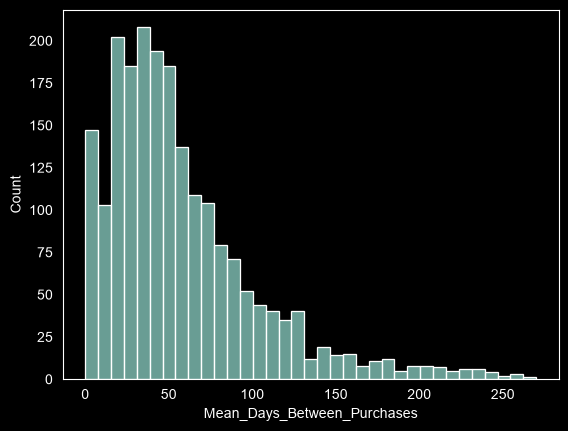

In [32]:
# Basic Information
print(f"Data type: {df["Mean_Days_Between_Purchases"].dtypes}")
print(f"Number of missing values: {df["Mean_Days_Between_Purchases"].isnull().sum()}")
print(
    f"Percentage of missing values: {df["Mean_Days_Between_Purchases"].isnull().mean() * 100}"
)

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Target"].corr(df["Mean_Days_Between_Purchases"])}")
print(
    f"Spearman Correlation: {df["Target"].rank().corr(df["Mean_Days_Between_Purchases"].rank())}"
)

# Median_Days_Between_Purchases

**Decision: DROP**

`Median_Days_Between_Purchases` represents the median number of days between a customer's purchases.

* **Correlation:** Pearson -0.113 and Spearman -0.081.
* **Missing values:** 37.97%. Missing because customers with only one purchase cannot have a median time between purchases.
* **Reason for dropping:** Weak relationship with target and a substantial amount of missing values.

In [26]:
# Basic Information
print(f"Data type: {df["Median_Days_Between_Purchases"].dtypes}")
print(f"Number of missing values: {df["Median_Days_Between_Purchases"].isnull().sum()}")
print(
    f"Percentage of missing values: {df["Median_Days_Between_Purchases"].isnull().mean() * 100}"
)

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Target"].corr(df["Median_Days_Between_Purchases"])}")
print(
    f"Spearman Correlation: {df["Target"].rank().corr(df["Median_Days_Between_Purchases"].rank())}"
)

Data type: float64
Number of missing values: 1274
Percentage of missing values: 37.97317436661699
---------------  Correlation  ---------------
Pearson Correlation: -0.11260405829967926
Spearman Correlation: -0.08130666176819304


# Max_Days_Between_Purchases

**Decision: DROP**

`Max_Days_Between_Purchases` represents the maximum number of days between a customer's purchases.

* **Correlation:** Pearson -0.029 and Spearman -0.013.
* **Missing values:** 37.97%.
* **Reason for dropping:** Negligible correlation with target, providing little evidence of predictive value.

In [28]:
# Basic Information
print(f"Data type: {df["Max_Days_Between_Purchases"].dtypes}")
print(f"Number of missing values: {df["Max_Days_Between_Purchases"].isnull().sum()}")
print(
    f"Percentage of missing values: {df["Max_Days_Between_Purchases"].isnull().mean() * 100}"
)

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Target"].corr(df["Max_Days_Between_Purchases"])}")
print(
    f"Spearman Correlation: {df["Target"].rank().corr(df["Max_Days_Between_Purchases"].rank())}"
)

Data type: float64
Number of missing values: 1274
Percentage of missing values: 37.97317436661699
---------------  Correlation  ---------------
Pearson Correlation: -0.029342875446143574
Spearman Correlation: -0.012974215730657544


# Min_Days_Between_Purchases

**Decision: DROP**

`Min_Days_Between_Purchases` represents the minimum number of days between a customer's purchases.

* **Correlation:** Pearson -0.141 and Spearman -0.112.
* **Missing Values:** 37.97%.
* **Reason for dropping:** Weak relationship with target and limited evidence of predictive value compared with stronger purchase-timing features.

In [29]:
# Basic Information
print(f"Data type: {df["Min_Days_Between_Purchases"].dtypes}")
print(f"Number of missing values: {df["Min_Days_Between_Purchases"].isnull().sum()}")
print(
    f"Percentage of missing values: {df["Min_Days_Between_Purchases"].isnull().mean() * 100}"
)

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Target"].corr(df["Min_Days_Between_Purchases"])}")
print(
    f"Spearman Correlation: {df["Target"].rank().corr(df["Min_Days_Between_Purchases"].rank())}"
)

Data type: float64
Number of missing values: 1274
Percentage of missing values: 37.97317436661699
---------------  Correlation  ---------------
Pearson Correlation: -0.14064492834208836
Spearman Correlation: -0.1116776202599581


# Std_Days_Between_Purchases

**Decision: DROP**

`Std_Days_Between_Purchases` represents the standard deviation of the number of days between a customer's purchases.

* **Correlation:** Pearson -0.107 and Spearman -0.062.
* **Missing Values:** 57.91%.
* **Reason for dropping:** Weak relationship with target and limited evidence of predictive value compared with stronger purchase-timing features.

In [33]:
# Basic Information
print(f"Data type: {df["Std_Days_Between_Purchases"].dtypes}")
print(f"Number of missing values: {df["Std_Days_Between_Purchases"].isnull().sum()}")
print(
    f"Percentage of missing values: {df["Std_Days_Between_Purchases"].isnull().mean() * 100}"
)

# Correlation
print("-" * 15, " Correlation ", "-" * 15)
print(f"Pearson Correlation: {df["Target"].corr(df["Std_Days_Between_Purchases"])}")
print(
    f"Spearman Correlation: {df["Target"].rank().corr(df["Std_Days_Between_Purchases"].rank())}"
)

Data type: float64
Number of missing values: 1943
Percentage of missing values: 57.913561847988085
---------------  Correlation  ---------------
Pearson Correlation: -0.10733033213013526
Spearman Correlation: -0.06192166920896584
